# Multi-Horizon Forecasts With Uncertainty, and Export for Power BI

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to December 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Forecast **several days ahead** with the **direct** method, and explain how it differs from the recursive method.
2. Explain **overlapping labels** and use the `gap` in walk-forward validation to prevent the leak they cause.
3. Measure how **forecast skill falls** and how **uncertainty grows** as the horizon increases.
4. Produce a complete **63-business-day forecast with an uncertainty band**, and export it as a CSV file for Power BI.
5. Describe a forecast to a decision maker honestly.

**Prerequisites:** Notebooks 3 and 4.

## Why This Notebook Exists

The lab scenario asks you to forecast the stock for the next 63 business days (one quarter) for a portfolio manager. You have seen in Notebook 3 that a classical model forecasts a nearly flat line for a quarter, with a very wide interval. In this notebook we do the job properly with the machine learning model from Notebook 4, and we measure how much a forecast for a quarter ahead is really worth.

### Two ways to forecast many days ahead

| Method | How it works | Weakness |
|:-------|:-------------|:---------|
| **Recursive** | Train one model to forecast **one** day ahead. To get day 2, feed its day-1 forecast back in as if it were real. Repeat 63 times. | Errors accumulate. It also needs the future values of every predictor (the VIX, oil, and so on) at every step, which we do not have. |
| **Direct** | Train a **separate** model for each horizon h. The model for h = 21 predicts the return from today to 21 days ahead, using only information available **today**. | More models to train. Forecasts for different horizons are independent and may not look smooth together. |

Because our model uses many predictors, we use the **direct** method.

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# On your own computer this block does nothing.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

from tslab import config
from tslab.data import load_market_data
from tslab.features import make_dataset, ALL_FEATURES
from tslab.validation import walk_forward_splits, walk_forward_predict
from tslab.metrics import out_of_sample_r2, rmse, directional_accuracy

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: Prepare the Data

We reuse the features from Notebook 4. Only the **target** changes: for a horizon of h days it is `log(close in h days / close today)`. The function `make_dataset(frame, horizon=h)` builds it.

In [3]:
frame = load_market_data()
latest_features = make_dataset(frame, horizon=1).iloc[[-1]][ALL_FEATURES]     # today's predictors: the basis of every forecast
last_close = float(frame["Close"].iloc[-1])
last_date = frame.index[-1]
print(f"Latest data: {last_date.date()}, closing price {last_close:.2f}")

Loaded 2953 trading days of NVDA, 2015-01-02 to 2026-09-30, with 7 predictor series.
Latest data: 2026-09-30, closing price 228.38


## Step 3: Overlapping Labels, a Quiet Source of Leakage

For a one-day target, the label in row t is the return from t to t+1. For a **21-day** target, the label in row t is the return from t to t+21. Two neighbouring rows, t and t+1, share 20 days of that return.

Now think about walk-forward validation. Suppose the first test row is day T. The last training row is day T-1, whose label is the return from T-1 to **T+20**. That label contains information about the 20 days **after** the start of the test period. The model has been trained on part of the test period's future.

The fix is a **gap**: leave out the last h-1 training rows, so that no training label reaches into the test block. In `walk_forward_splits`, set `gap = h - 1`. We check it explicitly.

In [4]:
h = 21
n = 200
no_gap = list(walk_forward_splits(n, initial_train=100, test_size=20, gap=0))[0]
with_gap = list(walk_forward_splits(n, initial_train=100, test_size=20, gap=h - 1))[0]

for name, (train, test) in {"No gap": no_gap, f"Gap of {h - 1}": with_gap}.items():
    last_label_reaches = train[-1] + h
    print(f"{name:10s}: last training row = {train[-1]}, its label reaches row {last_label_reaches}, "
          f"first test row = {test[0]}  ->  {'LEAK' if last_label_reaches > test[0] else 'safe'}")

No gap    : last training row = 99, its label reaches row 120, first test row = 100  ->  LEAK
Gap of 20 : last training row = 99, its label reaches row 120, first test row = 120  ->  safe


## Step 4: How Does Skill Change With the Horizon?

We evaluate horizons of 1, 5, 21 and 63 trading days (a day, a week, a month, a quarter) with walk-forward validation, using the gap. For each horizon we fit three models: the central forecast, and the 10th and 90th percentiles for an 80 percent forecast range.

The settings of the model are the cautious ones from Notebook 4: shallow trees, a small learning rate, regularisation.

In [5]:
def make_boosting(loss="squared_error", quantile=None):
    return HistGradientBoostingRegressor(
        loss=loss, quantile=quantile, max_depth=2, learning_rate=0.03, max_iter=150,
        min_samples_leaf=40, l2_regularization=1.0, random_state=config.SEED)

HORIZONS = [1, 5, 21, 63]
results = {}
started = time.time()

for horizon in HORIZONS:
    data_h = make_dataset(frame, horizon=horizon).dropna(subset=["target_return"])
    X_h, y_h = data_h[ALL_FEATURES], data_h["target_return"]
    splits_h = list(walk_forward_splits(len(data_h), config.INITIAL_TRAIN, config.TEST_SIZE, gap=horizon - 1))

    point = walk_forward_predict(lambda: make_boosting(), X_h, y_h, splits_h)
    low = walk_forward_predict(lambda: make_boosting("quantile", 0.10), X_h, y_h, splits_h)
    high = walk_forward_predict(lambda: make_boosting("quantile", 0.90), X_h, y_h, splits_h)

    m = point.notna()
    actual_ret = y_h[m]
    price_today = data_h.loc[m, "close"]
    actual_price = data_h.loc[m, "target_close"]
    results[horizon] = {
        "Test rows": int(m.sum()),
        "RMSE of the model ($)": rmse(actual_price, price_today * np.exp(point[m])),
        "RMSE of the naive forecast ($)": rmse(actual_price, price_today),
        "Out-of-sample R2 (returns)": out_of_sample_r2(actual_ret, point[m]),
        "Directional accuracy": directional_accuracy(actual_ret, point[m]),
        "Share inside the 10%-90% range": float(((actual_ret >= low[m]) & (actual_ret <= high[m])).mean()),
        "Average width of the range (% of price)": float((np.exp(high[m]) - np.exp(low[m])).mean() * 100),
    }
    print(f"  horizon {horizon:>2} days done ({time.time() - started:.0f} s)")

skill = pd.DataFrame(results).T
skill.index.name = "Horizon (trading days)"
skill.round(4)

  horizon  1 days done (19 s)
  horizon  5 days done (40 s)
  horizon 21 days done (63 s)
  horizon 63 days done (82 s)


,Test rows,RMSE of the model ($),RMSE of the naive forecast ($),Out-of-sample R2 (returns),Directional accuracy,Share inside the 10%-90% range,Average width of the range (% of price)
Horizon (trading days),,,,,,,
1,1753.0,2.6788,2.6779,-0.0139,0.5248,0.7536,6.6213
5,1745.0,5.7053,5.6083,-0.0693,0.5628,0.7507,15.1642
21,1713.0,11.8141,10.1175,-0.1914,0.6118,0.6591,29.1866
63,1629.0,26.0864,18.0874,-0.3660,0.6575,0.5556,52.7694


Read the table from top to bottom and ask these questions.

1. **Out-of-sample R2.** Does it ever become clearly positive? How does it change as the horizon grows?
2. **RMSE of the model against the naive forecast.** In dollars, how big is the gap, as a percentage of the error itself?
3. **Directional accuracy.** Is it meaningfully above 50 percent at any horizon?
4. **Share inside the range.** It should be about 80 percent. A lower value means that the range is too narrow (overconfident). A higher value means it is too wide.
5. **Width of the range.** It grows with the horizon. For a 63-day forecast, how many dollars (and what share of the price) is the range wide?

What the table shows for the AAPL data supplied with the lab: the model does not beat the naive forecast at horizons of 1, 5 and 21 days, and the share inside the range is below the 80 percent target at every horizon, so the ranges are too narrow. At 63 days the out-of-sample R2 is slightly positive and the directional accuracy looks impressive at about 62 percent, but be careful. AAPL rose in about 54 percent of the single days, 58 percent of the 5-day periods, 62 percent of the 21-day periods, and 64 percent of the 63-day periods in this sample. A rule that says "up" every day would therefore score about 64 percent at the 63-day horizon, **more** than the model. The directional accuracy of a model must always be compared with this base rate. Notice also that the R2 (on returns) and the RMSE (in dollars) do not agree at 63 days: the model has a slightly lower squared error on returns but a larger error in dollars. When two measures disagree, and both differences are small, the honest conclusion is that there is no clear skill.

Note one more thing: a **longer** horizon has **fewer independent** test periods. There are only about 30 non-overlapping quarters in a decade, so statements about the 63-day horizon rest on very few observations. A score that looks positive at a long horizon should be treated with more suspicion, not less.

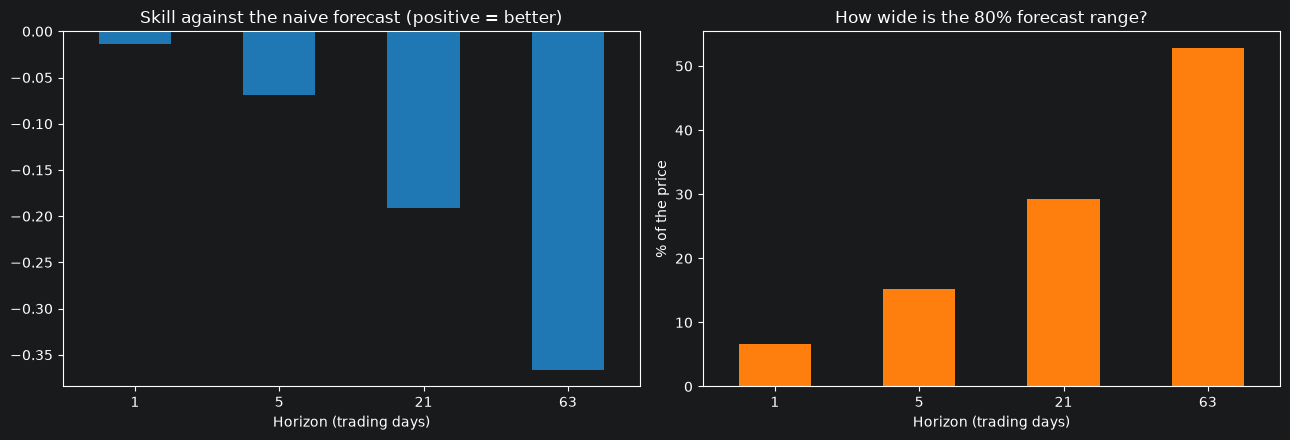

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
skill["Out-of-sample R2 (returns)"].plot.bar(ax=axes[0], color="tab:blue")
axes[0].axhline(0, color="black"); axes[0].set_title("Skill against the naive forecast (positive = better)")
axes[0].set_xlabel("Horizon (trading days)"); axes[0].tick_params(axis="x", rotation=0)
skill["Average width of the range (% of price)"].plot.bar(ax=axes[1], color="tab:orange")
axes[1].set_title("How wide is the 80% forecast range?"); axes[1].set_ylabel("% of the price")
axes[1].set_xlabel("Horizon (trading days)"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## Step 5: The Full 63-Day Forecast Path

We now train the final models, one for every horizon from 1 to 63 days, on **all** the history, and apply each of them to today's predictors. That gives a point forecast, a 10th percentile and a 90th percentile for each of the next 63 business days. This needs 63 x 3 = 189 small models, and takes a minute or so.

In [7]:
path_rows = []
started = time.time()
scaler = None

for horizon in range(1, 64):
    data_h = make_dataset(frame, horizon=horizon).dropna(subset=["target_return"])
    X_h, y_h = data_h[ALL_FEATURES], data_h["target_return"]
    scaler = StandardScaler().fit(X_h)
    X_scaled, today = scaler.transform(X_h), scaler.transform(latest_features)

    point = make_boosting().fit(X_scaled, y_h).predict(today)[0]
    low = make_boosting("quantile", 0.10).fit(X_scaled, y_h).predict(today)[0]
    high = make_boosting("quantile", 0.90).fit(X_scaled, y_h).predict(today)[0]

    # Quantile models are fitted separately, so on rare occasions they can cross. Sort them to keep the range valid.
    low, point, high = sorted([low, point, high])

    path_rows.append({
        "horizon_days": horizon,
        "date": last_date + pd.offsets.BDay(horizon),
        "forecast_close": last_close * np.exp(point),
        "lower_10": last_close * np.exp(low),
        "upper_90": last_close * np.exp(high),
    })
print(f"Done in {time.time() - started:.0f} seconds")

forecast_path = pd.DataFrame(path_rows).set_index("date")
forecast_path.round(2).iloc[[0, 4, 20, 41, 62]]

Done in 45 seconds


,horizon_days,forecast_close,lower_10,upper_90
date,,,,
2026-10-01,1,228.88,223.65,234.26
2026-10-07,5,232.22,216.67,245.36
2026-10-29,21,234.66,209.84,283.25
2026-11-27,42,240.98,194.43,299.54
2026-12-28,63,250.28,196.47,338.63


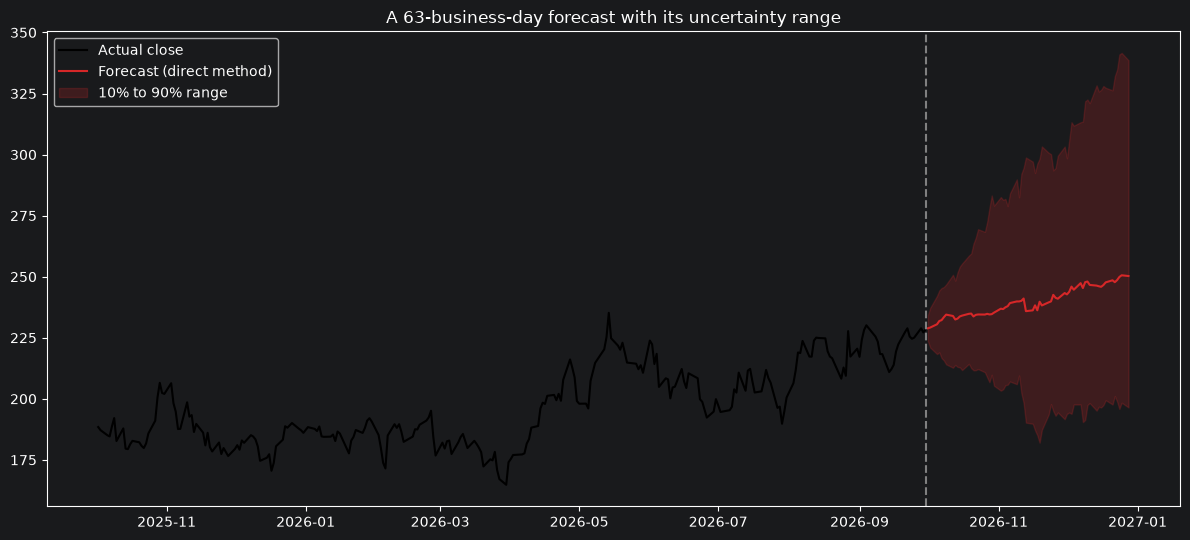

In [8]:
history = frame["Close"].iloc[-250:]

plt.figure(figsize=(12, 5.5))
plt.plot(history, color="black", label="Actual close")
plt.plot(forecast_path["forecast_close"], color="tab:red", label="Forecast (direct method)")
plt.fill_between(forecast_path.index, forecast_path["lower_10"], forecast_path["upper_90"],
                 color="tab:red", alpha=0.2, label="10% to 90% range")
plt.axvline(last_date, color="grey", linestyle="--")
plt.title("A 63-business-day forecast with its uncertainty range")
plt.legend(); plt.tight_layout(); plt.show()

The path may look slightly jagged from one horizon to the next. That is expected: every horizon is a **separate** model, trained on its own target, and nothing forces neighbouring horizons to agree. Do not read meaning into small wiggles in the central line.

Compare this chart with the ARIMA forecast in Notebook 3. The central line is again close to the current price, because that is what the evidence supports. What you gain over a single line is the **range**: it tells the portfolio manager how far the price could plausibly be after a month and after a quarter.

**How to describe it to the client.** A responsible statement would sound like this:

> "Over the next quarter our central estimate is that the price will be close to its current level. We cannot reliably say whether it will be higher or lower. There is an 80 percent chance, on our estimate, that the closing price in 63 days will fall between X and Y."

A forecast that is **honest about what it does not know** is more useful for risk management than a confident line that turns out to be wrong.

## Step 6: Save the Forecast for Power BI

We save two files in the `data` folder.

1. `forecast_basic.csv`: the 63-day forecast path (date, forecast, and the lower and upper values of the range).
2. `forecast_backtest.csv`: the **out-of-sample** one-day-ahead forecasts from the walk-forward test, next to the actual closing price. This shows the client how the model performed in the past, which is exactly the evidence needed to decide how far to trust the forecast.

In [9]:
os.makedirs(config.DATA_DIR, exist_ok=True)

# 1. The forecast path
export = forecast_path.reset_index()
export["last_actual_close"] = last_close
export["last_actual_date"] = last_date
export.to_csv(config.DATA_DIR / "forecast_basic.csv", index=False)
print("Saved", len(export), "rows to", config.DATA_DIR / "forecast_basic.csv")

# 2. The walk-forward record for horizon 1
data_1 = make_dataset(frame, horizon=1).dropna(subset=["target_return"])
splits_1 = list(walk_forward_splits(len(data_1), config.INITIAL_TRAIN, config.TEST_SIZE))
p = walk_forward_predict(lambda: make_boosting(), data_1[ALL_FEATURES], data_1["target_return"], splits_1)
lo = walk_forward_predict(lambda: make_boosting("quantile", 0.10), data_1[ALL_FEATURES], data_1["target_return"], splits_1)
hi = walk_forward_predict(lambda: make_boosting("quantile", 0.90), data_1[ALL_FEATURES], data_1["target_return"], splits_1)
m = p.notna()
backtest = pd.DataFrame({
    "date": frame.index[frame.index.get_indexer(data_1.index[m]) + 1],     # the trading day being forecast (the next row of the market table)
    "actual_close": data_1.loc[m, "target_close"].values,
    "naive_forecast": data_1.loc[m, "close"].values,
    "model_forecast": (data_1.loc[m, "close"] * np.exp(p[m])).values,
    "lower_10": (data_1.loc[m, "close"] * np.exp(np.minimum(lo[m], hi[m]))).values,
    "upper_90": (data_1.loc[m, "close"] * np.exp(np.maximum(lo[m], hi[m]))).values,
})
backtest.to_csv(config.DATA_DIR / "forecast_backtest.csv", index=False)
print("Saved", len(backtest), "rows to", config.DATA_DIR / "forecast_backtest.csv")
backtest.tail(3).round(2)

Saved 63 rows to C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\data\forecast_basic.csv
Saved 1753 rows to C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\data\forecast_backtest.csv


,date,actual_close,naive_forecast,model_forecast,lower_10,upper_90
1750,2026-09-28,228.86,225.07,225.55,220.57,231.15
1751,2026-09-29,227.21,228.86,229.34,222.79,234.74
1752,2026-09-30,228.38,227.21,227.66,220.91,232.60


A note on the dates in `forecast_backtest.csv`: the `date` column holds the **forecast target date**, which is the next trading day in the market table after the day on which the forecast was made. (Notice that this takes weekends and public holidays into account correctly, which adding one business day would not.)

### Importing the files into Power BI

1. In Power BI Desktop choose **Get data**, then **Text/CSV**, and select the file.
2. In the preview, check that `date` was detected as a **Date** column. If not, change its type in Power Query (*Transform data*).
3. Create a **line chart**. Put `date` on the X-axis and `forecast_close`, `lower_10` and `upper_90` as the values (for the forecast file), or `actual_close`, `naive_forecast` and `model_forecast` (for the back-test file).
4. For a shaded range, use an **area chart** for the lower and upper columns, or the *Analytics* pane of the line chart.
5. Add a **table** and **cards** with the main numbers (the last actual close, the forecast at 63 days, and the range).

## Step 7: Exercises

1. At which horizon is the model's skill highest, and at which is it lowest? How certain can you be, given how few independent test periods a 63-day horizon has?
2. Use the table in Step 4 to write the two-sentence statement for a client, that you would be comfortable defending, about the 21-day-ahead forecast.
3. In Step 3, change `gap = h - 1` to `gap = 0` in the walk-forward test for horizon 21 (in Step 4). Does the score improve? Why would the improvement be misleading?
4. Compare the width of the 63-day range with the width of the 1-day range. Is the ratio close to the square root of 63 (about 8)? What does that say about how risk grows with time?
5. Train the 21-day model with **Ridge** instead of gradient boosting. Which one has the better walk-forward score?
6. In Power BI, build a line chart showing the actual closing price for the past year, the forecast path, and the range, on a single chart.

## Summary

- Forecasting many days ahead with many predictors is best done with the **direct** method: one model for each horizon.
- Labels that span several days **overlap**. Use a `gap` in walk-forward validation or the results will be inflated.
- Skill (if any) falls as the horizon grows, while the **uncertainty** grows with it. Report the range.
- An honest forecast says how much we do not know.